In [1]:
#  Copyright (c) Microsoft Corporation.
#  Licensed under the MIT License.

## Local run notes

This notebook runs against the **local Qlib source tree** (the repository root that contains `examples/`), so no `pip install pyqlib` is needed. Use a kernel whose environment has the runtime dependencies (numpy, pandas, lightgbm, mlflow, plotly, ...) — e.g. `D:/ProgramData/miniconda3/envs/qlib`.

The Point-In-Time (PIT) subsection is optional: it needs a separate `financial` PIT store built by `scripts/data_collector/pit/collector.py` (baostock + network). When that store is absent the PIT cells print a skip message instead of failing, so the rest of the workflow still runs end to end.


In [2]:
import os
import sys
from pathlib import Path

# ---- Use the local qlib source code (repo root) instead of an installed package ----
_HERE = Path.cwd()
_REPO_ROOT = next(str(a) for a in [_HERE, *_HERE.parents] if (a / "qlib" / "__init__.py").exists())
if _REPO_ROOT not in sys.path:
    sys.path.insert(0, _REPO_ROOT)
print(f"Using qlib source from: {_REPO_ROOT}")

# MLflow 3.12+ disables the local file-store backend ("./mlruns") by default.
# qlib's default tracking URI is the file store, so opt back into it.
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")

import qlib

print(f"qlib loaded from: {qlib.__file__} (version {qlib.__version__})")


Using qlib source from: F:\treaWorkSpace\Qlib


qlib loaded from: F:\treaWorkSpace\Qlib\qlib\__init__.py (version 0.9.9.dev5)


# Introduction
Though users can automatically run the whole Quant research worklfow based on configurations with Qlib.

Some advanced users usally would like to carefully customize each component to explore more in Quant.

If you just want a simple example of Qlib. [Quick start](https://github.com/microsoft/qlib#quick-start) and [workflow_by_code](https://github.com/microsoft/qlib/blob/main/examples/workflow_by_code.ipynb) may be a better choice for you.

If you want to know more details about Quant research, this notebook may be a better place for you to start.

We hope this script could be a tutorial for users who are interested in the details of Quant.

This notebook tries to demonstrate how can we use Qlib to build components step by step. 

In [3]:
from pprint import pprint
from pathlib import Path
import pandas as pd

In [4]:
MARKET = "csi300"
BENCHMARK = "SH000300"
EXP_NAME = "tutorial_exp"

# Data

## Get data

Users can follow [the steps](https://github.com/microsoft/qlib/tree/main/scripts#download-qlib-data) to download data with CLI.

In this example we use the underlying API to automatically download data

In [5]:
from qlib.tests.data import GetData

GetData().qlib_data(exists_skip=True)

2026-11-15 16:37:39.763 | WARNING  | qlib.tests.data:qlib_data:195 - Data already exists: ~/.qlib/qlib_data/cn_data, the data download will be skipped
	If downloading is required: `exists_skip=False` or `change target_dir`


In [6]:
import qlib

qlib.init()

[34992:MainThread](2026-11-15 16:37:39,772) INFO - qlib.Initialization - [config.py:473] - default_conf: client.


[34992:MainThread](2026-11-15 16:37:40,947) INFO - qlib.Initialization - [__init__.py:82] - qlib successfully initialized based on client settings.


[34992:MainThread](2026-11-15 16:37:40,948) INFO - qlib.Initialization - [__init__.py:84] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/25441/.qlib/qlib_data/cn_data')}


## Inspect raw data

Currently, Qlib support several kinds of data source.

### Calendar

In [7]:
from qlib.data import D

print(D.calendar(start_time="2010-01-01", end_time="2017-12-31", freq="day")[:2])  # calendar data

[Timestamp('2010-01-04 00:00:00') Timestamp('2010-01-05 00:00:00')]


### Basic data

In [8]:
df = D.features(
    ["SH601216"],
    ["$open", "$high", "$low", "$close", "$factor"],
    start_time="2020-05-01",
    end_time="2020-05-31",
)

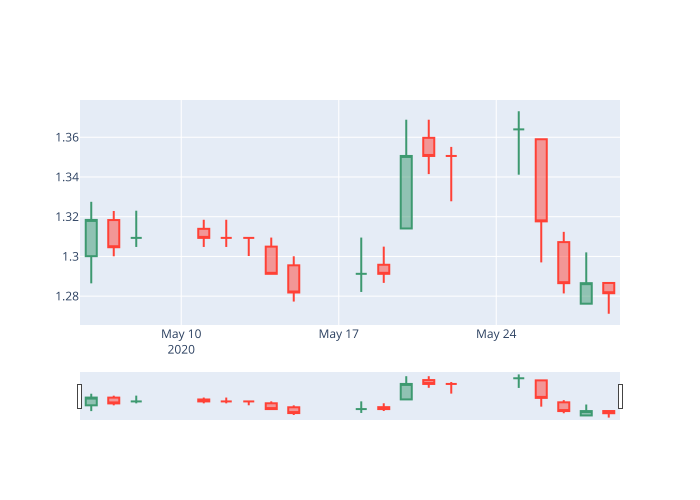

In [9]:
import plotly.graph_objects as go
import plotly.io as pio

# "svg" keeps the charts visible in a statically executed notebook; use "notebook"
# for interactive plots when running the cells live.
pio.renderers.default = "svg"
fig = go.Figure(
    data=[
        go.Candlestick(
            x=df.index.get_level_values("datetime"),
            open=df["$open"],
            high=df["$high"],
            low=df["$low"],
            close=df["$close"],
        )
    ]
)
fig.show()

### price adjustment

Maybe you think the price is not what it looks like in real world.

Due to the price adjustment, the price will be different from the real trading data .

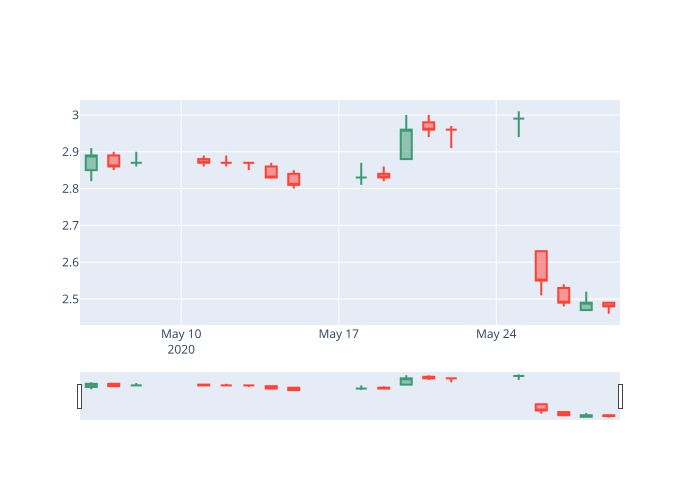

In [10]:
import plotly.graph_objects as go

fig = go.Figure(
    data=[
        go.Candlestick(
            x=df.index.get_level_values("datetime"),
            open=df["$open"] / df["$factor"],
            high=df["$high"] / df["$factor"],
            low=df["$low"] / df["$factor"],
            close=df["$close"] / df["$factor"],
        )
    ]
)
fig.show()

Please notice the price gap on [2020-05-26](http://vip.stock.finance.sina.com.cn/corp/view/vISSUE_ShareBonusDetail.php?stockid=601216&type=1&end_date=2020-05-20)

If we want to represent the change of assets value by price, adjust prices are necesary.
By default, Qlib stores the adjusted prices.

### Static universe V.S. dynamic universe

Dynamic universe

In [11]:
# dynamic universe
universe = D.list_instruments(D.instruments("csi300"), start_time="2010-01-01", end_time="2020-12-31")
pprint(universe)

{'SH600000': [(Timestamp('2010-01-01 00:00:00'),
               Timestamp('2010-01-03 00:00:00')),
              (Timestamp('2010-01-04 00:00:00'),
               Timestamp('2010-06-30 00:00:00')),
              (Timestamp('2010-07-01 00:00:00'),
               Timestamp('2011-01-03 00:00:00')),
              (Timestamp('2011-01-04 00:00:00'),
               Timestamp('2011-06-30 00:00:00')),
              (Timestamp('2011-07-01 00:00:00'),
               Timestamp('2012-01-03 00:00:00')),
              (Timestamp('2012-01-04 00:00:00'),
               Timestamp('2012-07-01 00:00:00')),
              (Timestamp('2012-07-02 00:00:00'),
               Timestamp('2013-01-03 00:00:00')),
              (Timestamp('2013-01-04 00:00:00'),
               Timestamp('2013-06-30 00:00:00')),
              (Timestamp('2013-07-01 00:00:00'),
               Timestamp('2013-09-29 00:00:00')),
              (Timestamp('2013-09-30 00:00:00'),
               Timestamp('2013-12-30 00:00:00')),
          

(Timestamp('2015-06-30 00:00:00'),
               Timestamp('2015-12-30 00:00:00')),
              (Timestamp('2015-12-31 00:00:00'),
               Timestamp('2016-06-29 00:00:00')),
              (Timestamp('2016-06-30 00:00:00'),
               Timestamp('2016-12-29 00:00:00')),
              (Timestamp('2016-12-30 00:00:00'),
               Timestamp('2017-06-29 00:00:00')),
              (Timestamp('2017-06-30 00:00:00'),
               Timestamp('2017-12-28 00:00:00')),
              (Timestamp('2017-12-29 00:00:00'),
               Timestamp('2018-06-28 00:00:00')),
              (Timestamp('2018-06-29 00:00:00'),
               Timestamp('2018-12-27 00:00:00')),
              (Timestamp('2018-12-28 00:00:00'),
               Timestamp('2019-06-27 00:00:00')),
              (Timestamp('2019-06-28 00:00:00'),
               Timestamp('2019-12-30 00:00:00')),
              (Timestamp('2019-12-31 00:00:00'),
               Timestamp('2020-06-29 00:00:00')),
              (Timestamp

In [12]:
print(len(universe))

692


Qlib use dynamic universe by default.

csi100 has around 100 stocks each day(it is not that accurate due to the low precision of data).

**Local run note:** the community qlib data bundle ships `all`, `csi300`, `csi500`, `csi800`, `csi1000` and `csiall` only — there is no `csi100.txt` — so this demo uses `csi300` as the dynamic universe.


<Axes: xlabel='datetime'>

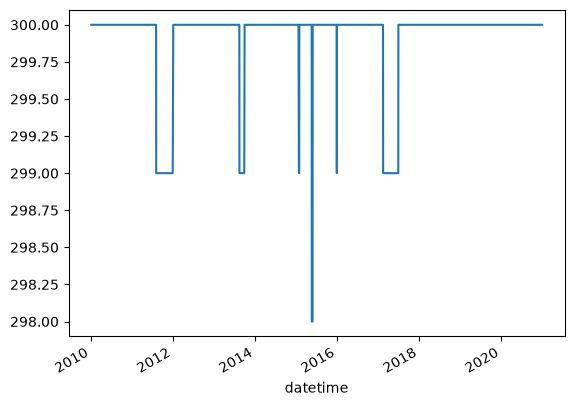

In [13]:
df = D.features(D.instruments("csi300"), ["$close"], start_time="2010-01-01", end_time="2020-12-31")
df.groupby("datetime").size().plot()

### Point-In-Time data

#### download data
NOTE: To run the test faster, we only download the data of two stocks

In [14]:
p = Path("~/.qlib/qlib_data/cn_data/financial").expanduser()

In [15]:
# The upstream notebook builds the PIT store here with the baostock collector (needs `baostock`,
# `lxml` and network access):
#   !cd ../../scripts/data_collector/pit/ && pip install -r requirements.txt
#   !cd ../../scripts/data_collector/pit/ && python collector.py download_data --source_dir ~/.qlib/stock_data/source/pit --start 2000-01-01 --end 2020-01-01 --interval quarterly --symbol_regex "^(600519|000725).*"
#   !cd ../../scripts/data_collector/pit/ && python collector.py normalize_data --interval quarterly --source_dir ~/.qlib/stock_data/source/pit --normalize_dir ~/.qlib/stock_data/source/pit_normalized
#   !cd ../../scripts/ && python dump_pit.py dump --csv_path ~/.qlib/stock_data/source/pit_normalized --qlib_dir ~/.qlib/qlib_data/cn_data --interval quarterly
# PIT data is optional for the rest of the tutorial, so only report whether the store already exists.
PIT_EXISTS = p.exists()
if not PIT_EXISTS:
    print(f"PIT store not found at {p} -> skipping the PIT download/query demo (everything below still runs)")


PIT store not found at C:\Users\25441\.qlib\qlib_data\cn_data\financial -> skipping the PIT download/query demo (everything below still runs)


#### querying data
using `roewa(performanceExpressROEWa,业绩快报净资产收益率ROE-加权)` as an example

If we want to get fundamental data `in the most recent quarter` daily, we can use following example.

Maitai release part of its fundamental data on [2019-07-13](http://www.cninfo.com.cn/new/disclosure/detail?stockCode=600519&announcementId=1206443183&orgId=gssh0600519&announcementTime=2019-07-13) and  release others on [2019-07-18](http://www.cninfo.com.cn/new/disclosure/detail?stockCode=600519&announcementId=1206456129&orgId=gssh0600519&announcementTime=2019-07-18)

In [16]:
if PIT_EXISTS:
    instruments = ["sh600519"]
    data = D.features(
        instruments,
        ["P($$roewa_q)"],
        start_time="2019-01-01",
        end_time="2019-07-19",
        freq="day",
    )
else:
    print("skipped: no local PIT data")


skipped: no local PIT data


In [17]:
data.tail(15) if PIT_EXISTS else None


### experss engine


In [18]:
D.features(
    ["sh600519"],
    ["(EMA($close, 12) - EMA($close, 26))/$close - EMA((EMA($close, 12) - EMA($close, 26))/$close, 9)/$close"],
)

(EMA($close, 12) - EMA($close, 26))/$close - EMA((EMA($close, 12) - EMA($close, 26))/$close, 9)/$close
instrument datetime                                                                                                          
sh600519   2001-08-27                                           0.000000                                                     
           2001-08-28                                           0.000370                                                     
           2001-08-29                                           0.000116                                                     
           2001-08-30                                           0.000491                                                     
           2001-08-31                                           0.000507                                                     
...                                                                  ...                                                     
           2026-10-19                                           0.004934                                                     
           2026-10-20                                           0.007078                                                     
           2026-10-21                                           0.007492                                                     
           2026-10-22                                           0.008119                                                     
           2026-10-23                                           0.009436                                                     

[6101 rows x 1 columns]


## Dataset loading and preprocessing 

Some heuristic principles of create features
- make the features comparable between instrumets: remove unit from the features.
- try to keep the distribution invariant
- keep the scale of features similar

### data loader

It's interface can be found [here](https://github.com/microsoft/qlib/blob/main/qlib/data/dataset/loader.py#L24) 

QlibDataLoader is an implementation which load data from Qlib's data source

In [19]:
from qlib.data.dataset.loader import QlibDataLoader

In [20]:
qdl = QlibDataLoader(config=(["$close / Ref($close, 10)"], ["RET10"]))

In [21]:
qdl.load(instruments=["sh600519"], start_time="20190101", end_time="20191231")

,,RET10
datetime,instrument,
2019-01-02,sh600519,1.014326
2019-01-03,sh600519,0.998409
2019-01-04,sh600519,1.041884
2019-01-07,sh600519,1.053944
2019-01-08,sh600519,1.065879
...,...,...
2019-12-25,sh600519,0.978188
2019-12-26,sh600519,0.998328
2019-12-27,sh600519,1.000000


### data handler

finance data can't be perfect.

We have to process them before feeding them into Models

In [22]:
df = qdl.load(instruments=["sh600519"], start_time="20190101", end_time="20191231")

In [23]:
df.isna().sum()

RET10    0
dtype: int64

<Axes: ylabel='Frequency'>

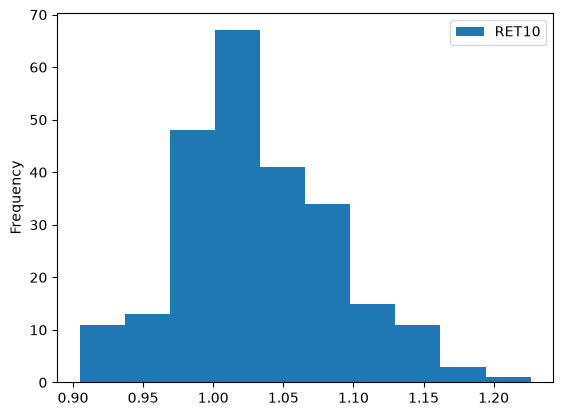

In [24]:
df.plot(kind="hist")

Datahander is responsible for data preprocessing and provides data fetching interface 



In [25]:
from qlib.data.dataset.handler import DataHandlerLP
from qlib.data.dataset.processor import ZScoreNorm, Fillna

In [26]:
# NOTE: normally, the training & validation time range will be  `fit_start_time` ， `fit_end_time`
# however，all the components are decomposed, so the training & validation time range is unknown when preprocessing.
dh = DataHandlerLP(
    instruments=["sh600519"],
    start_time="20170101",
    end_time="20191231",
    infer_processors=[
        ZScoreNorm(fit_start_time="20170101", fit_end_time="20181231"),
        Fillna(),
    ],
    data_loader=qdl,
)

[34992:MainThread](2026-11-15 16:38:05,690) INFO - qlib.timer - [log.py:127] - Time cost: 0.012s | Loading data Done


[34992:MainThread](2026-11-15 16:38:05,699) INFO - qlib.timer - [log.py:127] - Time cost: 0.006s | ZScoreNorm Done


[34992:MainThread](2026-11-15 16:38:05,700) INFO - qlib.timer - [log.py:127] - Time cost: 0.000s | Fillna Done


[34992:MainThread](2026-11-15 16:38:05,702) INFO - qlib.timer - [log.py:127] - Time cost: 0.010s | fit & process data Done


[34992:MainThread](2026-11-15 16:38:05,703) INFO - qlib.timer - [log.py:127] - Time cost: 0.026s | Init data Done


In [27]:
df = dh.fetch()

In [28]:
df

,,RET10
datetime,instrument,
2017-01-03,sh600519,0.213983
2017-01-04,sh600519,1.102969
2017-01-05,sh600519,0.708071
2017-01-06,sh600519,1.115077
2017-01-09,sh600519,1.294502
...,...,...
2019-12-25,sh600519,-0.617778
2019-12-26,sh600519,-0.270180
2019-12-27,sh600519,-0.241331


In [29]:
df.isna().sum()

RET10    0
dtype: int64

<Axes: ylabel='Frequency'>

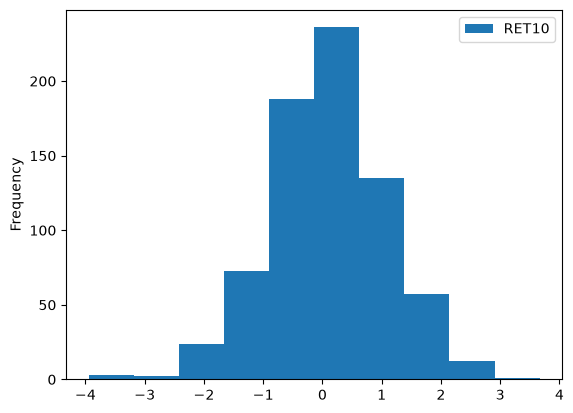

In [30]:
df.plot(kind="hist")

### dataset

#### basic dataset

In [31]:
from qlib.data.dataset import DatasetH, TSDatasetH

In [32]:
ds = DatasetH(dh, segments={"train": ("20180101", "20181231"), "valid": ("20190101", "20191231")})

In [33]:
ds.prepare("train")

,,RET10
datetime,instrument,
2018-01-02,sh600519,0.745785
2018-01-03,sh600519,1.020412
2018-01-04,sh600519,1.072983
2018-01-05,sh600519,1.192017
2018-01-08,sh600519,1.507689
...,...,...
2018-12-24,sh600519,-0.517275
2018-12-25,sh600519,-0.750493
2018-12-26,sh600519,-1.088699


In [34]:
ds.prepare("valid")

,,RET10
datetime,instrument,
2019-01-02,sh600519,0.005911
2019-01-03,sh600519,-0.268787
2019-01-04,sh600519,0.481520
2019-01-07,sh600519,0.689656
2019-01-08,sh600519,0.895632
...,...,...
2019-12-25,sh600519,-0.617778
2019-12-26,sh600519,-0.270180
2019-12-27,sh600519,-0.241331


#### Time Series Dataset

For different model, the required dataset format will be different.

For example, Qlib provides a Time Series Dataset(TSDatasetH) to help users to create time-series dataset.

In [35]:
ds = TSDatasetH(
    step_len=10,
    handler=dh,
    segments={"train": ("20180101", "20181231"), "valid": ("20190101", "20191231")},
)
train_sampler = ds.prepare("train")

In [36]:
train_sampler

In [37]:
train_sampler[0]  # Retrieving the first example

array([[ 0.6892426 ],
       [ 1.4126742 ],
       [ 1.5791095 ],
       [ 1.2894925 ],
       [ 0.7430299 ],
       [ 0.54007864],
       [-0.34542984],
       [ 1.1647081 ],
       [ 0.91225094],
       [ 0.7457847 ]], dtype=float32)

In [38]:
train_sampler["2018-01-08", "sh600519"]  # get the time series by <'timestamp', 'instrument_id'> index

array([[ 0.7430299 ],
       [ 0.54007864],
       [-0.34542984],
       [ 1.1647081 ],
       [ 0.91225094],
       [ 0.7457847 ],
       [ 1.020412  ],
       [ 1.0729834 ],
       [ 1.1920174 ],
       [ 1.5076888 ]], dtype=float32)

### Off-the-shelf dataset

Qlib integrated some dataset alreadly

In [39]:
handler_kwargs = {
    "start_time": "2008-01-01",
    "end_time": "2020-08-01",
    "fit_start_time": "2008-01-01",
    "fit_end_time": "2014-12-31",
    "instruments": MARKET,
}
handler_conf = {
    "class": "Alpha158",
    "module_path": "qlib.contrib.data.handler",
    "kwargs": handler_kwargs,
}
pprint(handler_conf)

{'class': 'Alpha158',
 'kwargs': {'end_time': '2020-08-01',
            'fit_end_time': '2014-12-31',
            'fit_start_time': '2008-01-01',
            'instruments': 'csi300',
            'start_time': '2008-01-01'},
 'module_path': 'qlib.contrib.data.handler'}


In [40]:
from qlib.utils import init_instance_by_config

In [41]:
hd = init_instance_by_config(handler_conf)

[34992:MainThread](2026-11-15 16:39:11,839) INFO - qlib.timer - [log.py:127] - Time cost: 65.849s | Loading data Done


[34992:MainThread](2026-11-15 16:39:12,373) INFO - qlib.timer - [log.py:127] - Time cost: 0.224s | DropnaLabel Done


[34992:MainThread](2026-11-15 16:39:17,324) INFO - qlib.timer - [log.py:127] - Time cost: 4.952s | CSZScoreNorm Done


[34992:MainThread](2026-11-15 16:39:17,360) INFO - qlib.timer - [log.py:127] - Time cost: 5.518s | fit & process data Done


[34992:MainThread](2026-11-15 16:39:17,362) INFO - qlib.timer - [log.py:127] - Time cost: 71.370s | Init data Done


Using config to create instance is a highly frequently used practice in Qlib (e.g. the [workflows configurations](https://github.com/microsoft/qlib/blob/main/examples/benchmarks/LightGBM/workflow_config_lightgbm_Alpha158.yaml) are based on it).


The above configuration is the same as the code below

In [42]:
from qlib.contrib.data.handler import Alpha158

hd = Alpha158(**handler_kwargs)

[34992:MainThread](2026-11-15 16:40:28,002) INFO - qlib.timer - [log.py:127] - Time cost: 70.630s | Loading data Done


[34992:MainThread](2026-11-15 16:40:28,663) INFO - qlib.timer - [log.py:127] - Time cost: 0.291s | DropnaLabel Done


[34992:MainThread](2026-11-15 16:40:35,195) INFO - qlib.timer - [log.py:127] - Time cost: 6.530s | CSZScoreNorm Done


[34992:MainThread](2026-11-15 16:40:35,246) INFO - qlib.timer - [log.py:127] - Time cost: 7.244s | fit & process data Done


[34992:MainThread](2026-11-15 16:40:35,249) INFO - qlib.timer - [log.py:127] - Time cost: 77.877s | Init data Done


This dataset has the same structure as the simple one with 1 column  we created just now.

In [43]:
df = hd.fetch()

In [44]:
df

KMID      KLEN     KMID2       KUP      KUP2  \
datetime   instrument                                                     
2008-01-02 SH600000    0.010377  0.061132  0.169753  0.028302  0.462962   
           SH600001    0.032020  0.080049  0.400000  0.027094  0.338462   
           SH600004    0.057279  0.059666  0.960000  0.002387  0.040000   
           SH600005   -0.024760  0.044972 -0.550563  0.005053  0.112359   
           SH600006    0.012673  0.040323  0.314285  0.008065  0.200001   
...                         ...       ...       ...       ...       ...   
2020-07-31 SZ300413    0.011740  0.040868  0.287273  0.018874  0.461818   
           SZ300433    0.030103  0.048605  0.619354  0.014111  0.290323   
           SZ300498   -0.003775  0.023490 -0.160713  0.012164  0.517857   
           SZ300601    0.003839  0.067009  0.057296  0.017991  0.268487   
           SZ300628   -0.016719  0.040313 -0.414730  0.017187  0.426356   

                           KLOW     KLOW2      KSFT     KSFT2     OPEN0  ...  \
datetime   instrument                                                    ...   
2008-01-02 SH600000    0.022453  0.367285  0.004528  0.074076  0.989729  ...   
           SH600001    0.020936  0.261538  0.025862  0.323076  0.968974  ...   
           SH600004    0.000000  0.000000  0.054893  0.920000  0.945824  ...   
           SH600005    0.015159  0.337079 -0.014654 -0.325843  1.025389  ...   
           SH600006    0.019585  0.485715  0.024193  0.599998  0.987486  ...   
...                         ...       ...       ...       ...       ...  ...   
2020-07-31 SZ300413    0.010254  0.250908  0.003121  0.076364  0.988396  ...   
           SZ300433    0.004390  0.090323  0.020383  0.419354  0.970776  ...   
           SZ300498    0.007550  0.321429 -0.008389 -0.357141  1.003789  ...   
           SZ300601    0.045179  0.674217  0.031027  0.463026  0.996175  ...   
           SZ300628    0.006406  0.158914 -0.027500 -0.682171  1.017003  ...   

                        VSUMN10   VSUMN20   VSUMN30   VSUMN60    VSUMD5  \
datetime   instrument                                                     
2008-01-02 SH600000    0.550646  0.490807  0.485961  0.510337 -0.022324   
           SH600001    0.283440  0.381567  0.395191  0.498146  0.617548   
           SH600004    0.328855  0.392342  0.423973  0.514943  0.633304   
           SH600005    0.488788  0.568366  0.545217  0.558634 -0.513450   
           SH600006    0.522801  0.433382  0.494534  0.524931 -0.063987   
...                         ...       ...       ...       ...       ...   
2020-07-31 SZ300413    0.559083  0.514447  0.531430  0.492427 -0.421074   
           SZ300433    0.506856  0.507546  0.466976  0.490192 -0.001736   
           SZ300498    0.565266  0.523500  0.489538  0.491605 -0.541263   
           SZ300601    0.268607  0.387656  0.426475  0.465822  0.539503   
           SZ300628    0.510554  0.482802  0.511882  0.507976 -0.073147   

                        VSUMD10   VSUMD20   VSUMD30   VSUMD60    LABEL0  
datetime   instrument                                                    
2008-01-02 SH600000   -0.101293  0.018385  0.028078 -0.020674  0.042108  
           SH600001    0.433119  0.236867  0.209618  0.003707  0.028992  
           SH600004    0.342289  0.215315  0.152055 -0.029886  0.000000  
           SH600005    0.022424 -0.136732 -0.090433 -0.117268 -0.012579  
           SH600006   -0.045603  0.133235  0.010933 -0.049863 -0.008891  
...                         ...       ...       ...       ...       ...  
2020-07-31 SZ300413   -0.118167 -0.028894 -0.062861  0.015147 -0.038817  
           SZ300433   -0.013711 -0.015093  0.066048  0.019616 -0.031109  
           SZ300498   -0.130532 -0.047001  0.020924  0.016790 -0.006606  
           SZ300601    0.462787  0.224688  0.147049  0.068355  0.091076  
           SZ300628   -0.021108  0.034397 -0.023764 -0.015951  0.004295  

[918005 rows x 159 columns]

In [45]:
hd.data_loader

In [46]:
hd.data_loader.fields

{'feature': (['($close-$open)/$open',
   '($high-$low)/$open',
   '($close-$open)/($high-$low+1e-12)',
   '($high-Greater($open, $close))/$open',
   '($high-Greater($open, $close))/($high-$low+1e-12)',
   '(Less($open, $close)-$low)/$open',
   '(Less($open, $close)-$low)/($high-$low+1e-12)',
   '(2*$close-$high-$low)/$open',
   '(2*$close-$high-$low)/($high-$low+1e-12)',
   '$open/$close',
   '$high/$close',
   '$low/$close',
   '$vwap/$close',
   'Ref($close, 5)/$close',
   'Ref($close, 10)/$close',
   'Ref($close, 20)/$close',
   'Ref($close, 30)/$close',
   'Ref($close, 60)/$close',
   'Mean($close, 5)/$close',
   'Mean($close, 10)/$close',
   'Mean($close, 20)/$close',
   'Mean($close, 30)/$close',
   'Mean($close, 60)/$close',
   'Std($close, 5)/$close',
   'Std($close, 10)/$close',
   'Std($close, 20)/$close',
   'Std($close, 30)/$close',
   'Std($close, 60)/$close',
   'Slope($close, 5)/$close',
   'Slope($close, 10)/$close',
   'Slope($close, 20)/$close',
   'Slope($close, 30)/

#### some details

The training data may not be the same as the test data.

e.g.
- the training dataset and test dataset use a different fitlering rules,  data processing

In [47]:
hd.learn_processors

In [48]:
hd.infer_processors

[]

In [49]:
hd.process_type  # appending type

'append'

In [50]:
hd.fetch(col_set="label", data_key=hd.DK_L)

LABEL0
datetime   instrument          
2008-01-02 SH600000    1.243745
           SH600001    0.745596
           SH600004   -0.355491
           SH600005   -0.833243
           SH600006   -0.693145
...                         ...
2020-07-31 SZ300413   -1.520037
           SZ300433   -1.214285
           SZ300498   -0.242339
           SZ300601    3.632376
           SZ300628    0.190054

[883807 rows x 1 columns]

In [51]:
hd.fetch(col_set="label", data_key=hd.DK_I)

LABEL0
datetime   instrument          
2008-01-02 SH600000    0.042108
           SH600001    0.028992
           SH600004    0.000000
           SH600005   -0.012579
           SH600006   -0.008891
...                         ...
2020-07-31 SZ300413   -0.038817
           SZ300433   -0.031109
           SZ300498   -0.006606
           SZ300601    0.091076
           SZ300628    0.004295

[918005 rows x 1 columns]

In [52]:
dataset_conf = {
    "class": "DatasetH",
    "module_path": "qlib.data.dataset",
    "kwargs": {
        "handler": hd,
        "segments": {
            "train": ("2008-01-01", "2014-12-31"),
            "valid": ("2015-01-01", "2016-12-31"),
            "test": ("2017-01-01", "2020-08-01"),
        },
    },
}

In [53]:
dataset = init_instance_by_config(dataset_conf)

# Model Training & Inference

[Model interface](https://github.com/microsoft/qlib/blob/main/qlib/model/base.py)

In [54]:
from qlib.workflow import R
from qlib.workflow.record_temp import SignalRecord, PortAnaRecord, SigAnaRecord

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [55]:
model = init_instance_by_config(
    {
        "class": "LGBModel",
        "module_path": "qlib.contrib.model.gbdt",
        "kwargs": {
            "loss": "mse",
            "colsample_bytree": 0.8879,
            "learning_rate": 0.0421,
            "subsample": 0.8789,
            "lambda_l1": 205.6999,
            "lambda_l2": 580.9768,
            "max_depth": 8,
            "num_leaves": 210,
            "num_threads": 20,
        },
    }
)

In [56]:
# start exp to train model
with R.start(experiment_name=EXP_NAME):
    model.fit(dataset)
    R.save_objects(trained_model=model)

    rec = R.get_recorder()
    rid = rec.id  # save the record id

    # Inference and saving signal
    sr = SignalRecord(model, dataset, rec)
    sr.generate()

[34992:MainThread](2026-11-15 16:40:38,512) INFO - qlib.workflow - [exp.py:258] - Experiment 701955990769099664 starts running ...


[34992:MainThread](2026-11-15 16:40:38,958) INFO - qlib.workflow - [recorder.py:355] - Recorder 1df9d0ba1694499cbdb7c0ae51c9ec67 starts running under Experiment 701955990769099664 ...


Training until validation scores don't improve for 50 rounds

[20]	train's l2: 0.990335	valid's l2: 0.994213

[40]	train's l2: 0.986521	valid's l2: 0.993621

[60]	train's l2: 0.983878	valid's l2: 0.993214

... (5 outputs left out)

[34992:MainThread](2026-11-15 16:41:05,649) INFO - qlib.workflow - [record_temp.py:204] - Signal record 'pred.pkl' has been saved as the artifact of the Experiment 701955990769099664


'The following are prediction results of the LGBModel model.'

                          score
datetime   instrument          
2017-01-03 SH600000   -0.045284
           SH600005   -0.100650
           SH600008    0.003965
           SH600009    0.010925
           SH600010   -0.010727

[34992:MainThread](2026-11-15 16:41:05,695) INFO - qlib.timer - [log.py:127] - Time cost: 0.000s | waiting `async_log` Done


# Evaluation:
- Signal-based
- Portfolio-based: backtest 

In [57]:
###################################
# prediction, backtest & analysis
###################################
port_analysis_config = {
    "executor": {
        "class": "SimulatorExecutor",
        "module_path": "qlib.backtest.executor",
        "kwargs": {
            "time_per_step": "day",
            "generate_portfolio_metrics": True,
        },
    },
    "strategy": {
        "class": "TopkDropoutStrategy",
        "module_path": "qlib.contrib.strategy.signal_strategy",
        "kwargs": {
            "signal": "<PRED>",
            "topk": 50,
            "n_drop": 5,
        },
    },
    "backtest": {
        "start_time": "2017-01-01",
        "end_time": "2020-08-01",
        "account": 100000000,
        "benchmark": BENCHMARK,
        "exchange_kwargs": {
            "freq": "day",
            "limit_threshold": 0.095,
            "deal_price": "close",
            "open_cost": 0.0005,
            "close_cost": 0.0015,
            "min_cost": 5,
        },
    },
}

# backtest and analysis
with R.start(experiment_name=EXP_NAME, recorder_id=rid, resume=True):
    # signal-based analysis
    rec = R.get_recorder()
    sar = SigAnaRecord(rec)
    sar.generate()

    #  portfolio-based analysis: backtest
    par = PortAnaRecord(rec, port_analysis_config, "day")
    par.generate()

[34992:MainThread](2026-11-15 16:41:05,733) INFO - qlib.workflow - [exp.py:258] - Experiment 701955990769099664 starts running ...


[34992:MainThread](2026-11-15 16:41:05,769) INFO - qlib.workflow - [recorder.py:355] - Recorder 1df9d0ba1694499cbdb7c0ae51c9ec67 starts running under Experiment 701955990769099664 ...


{

'IC'

: 

np.float64(0.04862486955458371)

... (26 outputs left out)

[34992:MainThread](2026-11-15 16:42:21,023) INFO - qlib.workflow - [record_temp.py:552] - Indicator analysis record 'indicator_analysis_1day.pkl' has been saved as the artifact of the Experiment 701955990769099664


'The following are analysis results of indicators(1day).'

     value
ffr    1.0
pa     0.0
pos    0.0

[34992:MainThread](2026-11-15 16:42:21,910) INFO - qlib.timer - [log.py:127] - Time cost: 0.001s | waiting `async_log` Done


# Loading results & Analysis

## loading data
Because Qlib leverage MLflow to save model & data.
All the data can be access by `mlflow ui`

In [58]:
# load recorder
recorder = R.get_recorder(recorder_id=rid, experiment_name=EXP_NAME)

In [59]:
# load previous results
pred_df = recorder.load_object("pred.pkl")
report_normal_df = recorder.load_object("portfolio_analysis/report_normal_1day.pkl")
positions = recorder.load_object("portfolio_analysis/positions_normal_1day.pkl", trusted=True)
analysis_df = recorder.load_object("portfolio_analysis/port_analysis_1day.pkl")

C:\Users\25441\AppData\Local\Temp\ipykernel_34992\3601791836.py:4: UnsafeArtifactWarning:

Loading a trusted pickle artifact may execute arbitrary code. Only use trusted=True when the artifact source and storage are trusted.



In [60]:
# Previous Model can be loaded. but it is not used.
loaded_model = recorder.load_object("trained_model", trusted=True)
loaded_model

C:\Users\25441\AppData\Local\Temp\ipykernel_34992\2975611186.py:2: UnsafeArtifactWarning:

Loading a trusted pickle artifact may execute arbitrary code. Only use trusted=True when the artifact source and storage are trusted.



In [61]:
from qlib.contrib.report import analysis_model, analysis_position
# qlib's report helpers call plotly's init_notebook_mode() for every figure, which resets
# the renderer to "notebook" and emits output a plain notebook viewer cannot draw.
# Disable it so the inline "svg" renderer configured earlier is used instead.
import plotly.io as pio
import plotly.offline as py_offline

py_offline.init_notebook_mode = lambda *args, **kwargs: None
pio.renderers.default = "svg"


## analysis position

### report

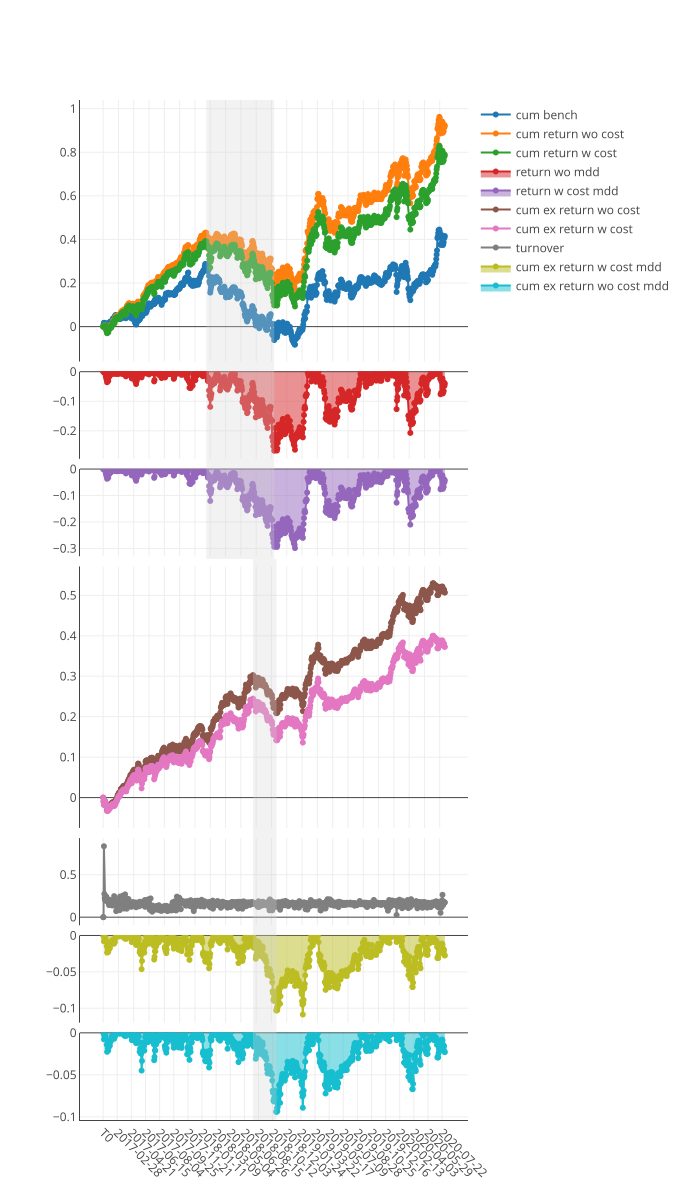

In [62]:
analysis_position.report_graph(report_normal_df)

### risk analysis

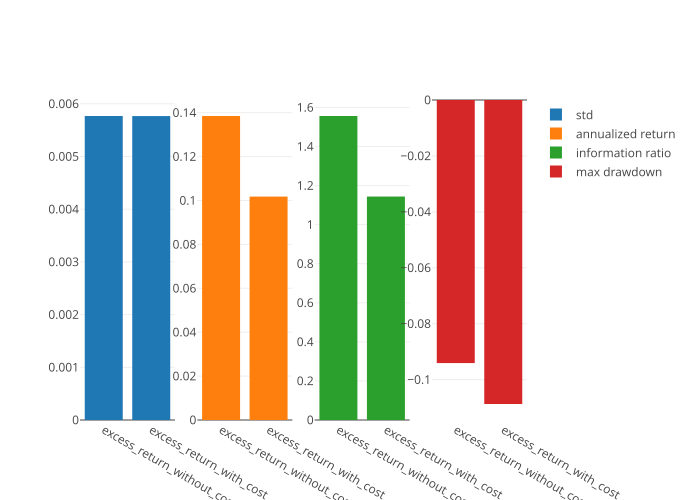

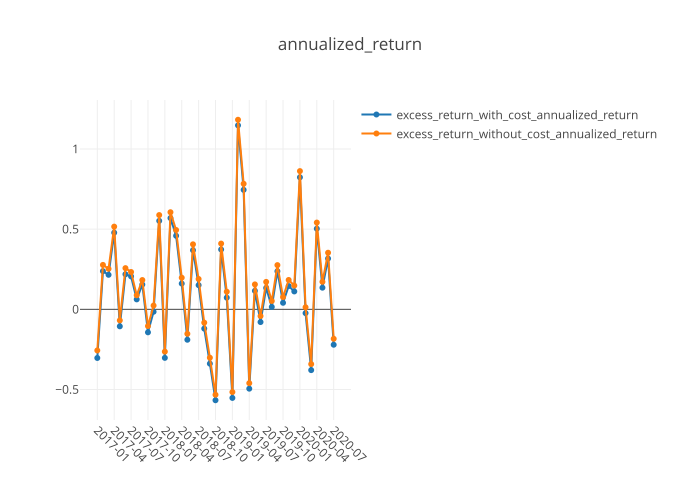

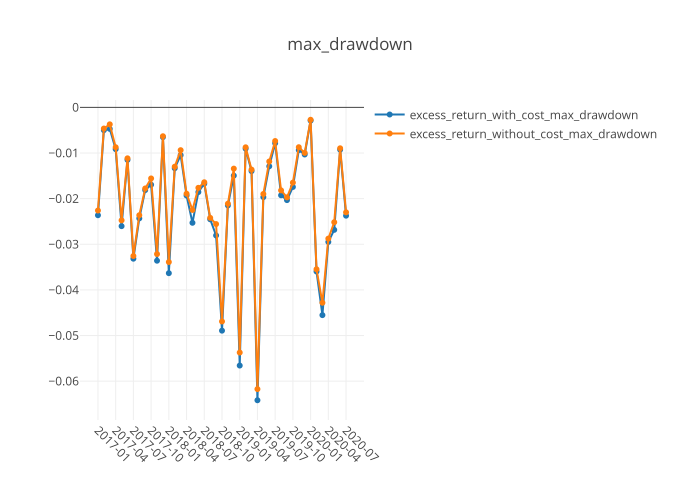

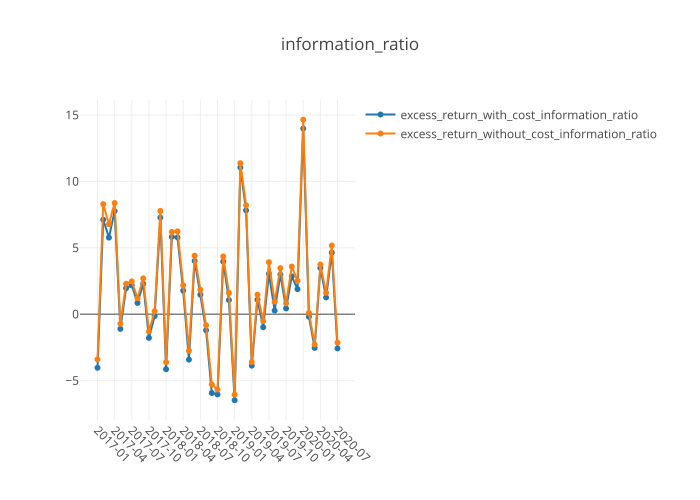

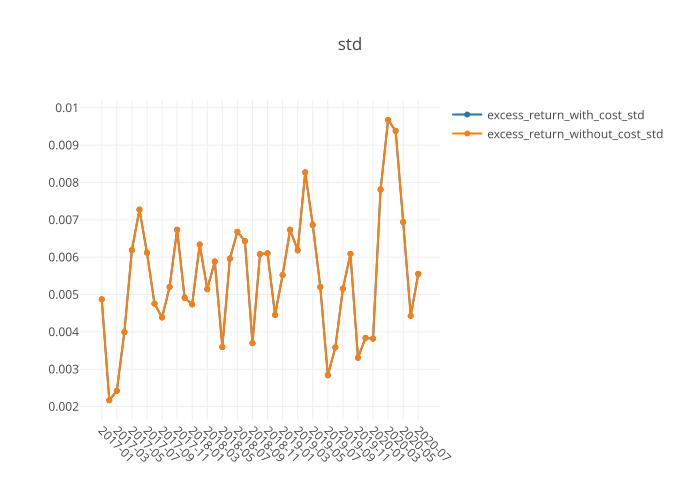

In [63]:
analysis_position.risk_analysis_graph(analysis_df, report_normal_df)

## analysis model

In [64]:
label_df = dataset.prepare("test", col_set="label")
label_df.columns = ["label"]

### score IC

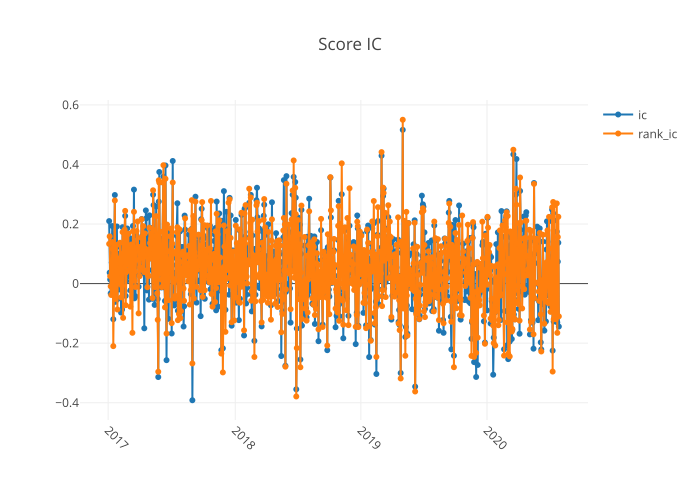

In [65]:
pred_label = pd.concat([label_df, pred_df], axis=1, sort=True).reindex(label_df.index)
analysis_position.score_ic_graph(pred_label)

### model performance

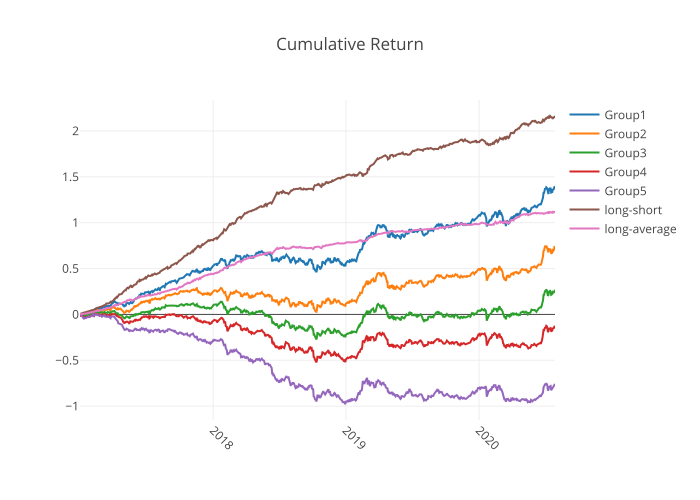

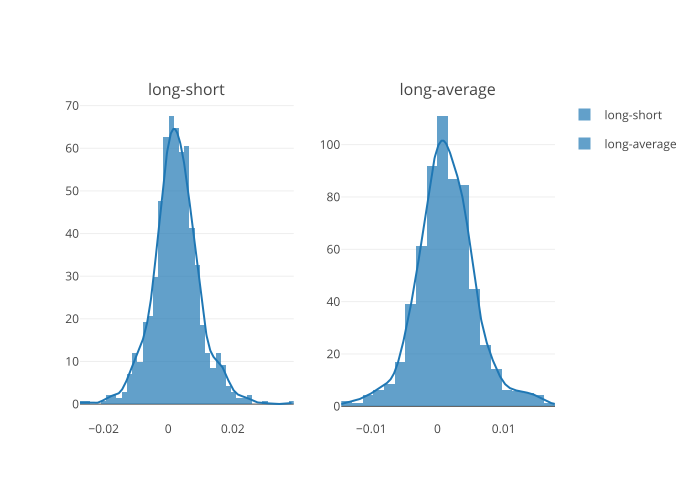

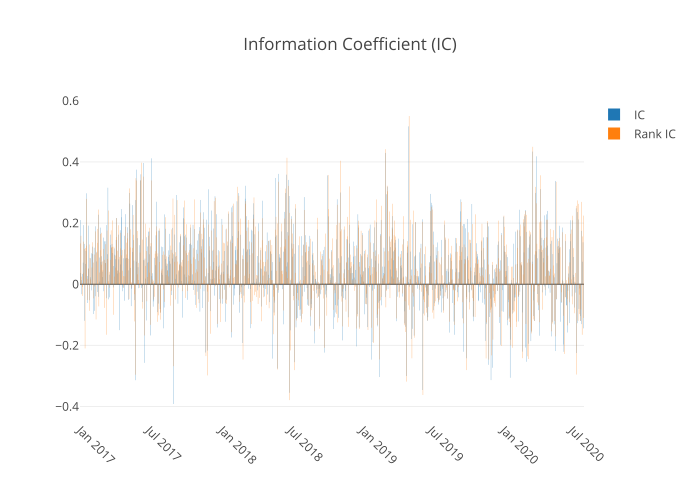

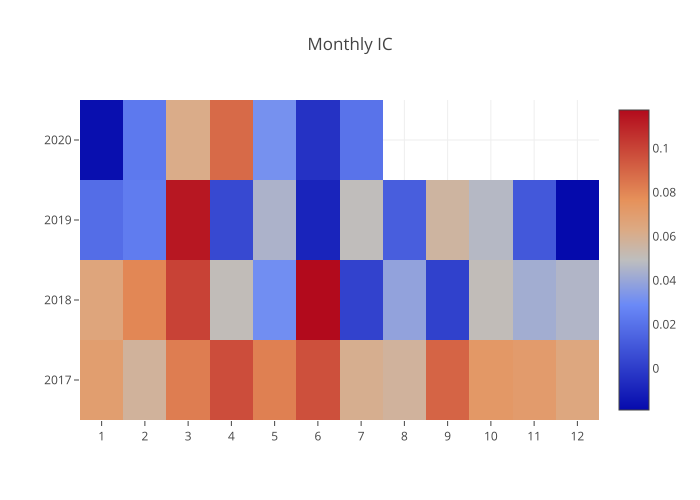

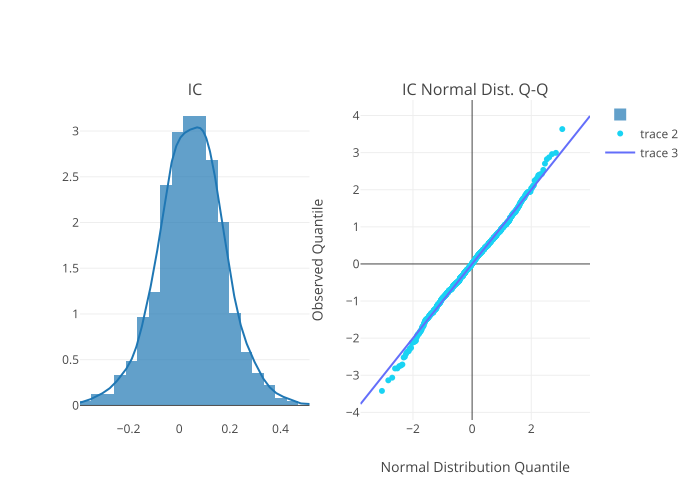

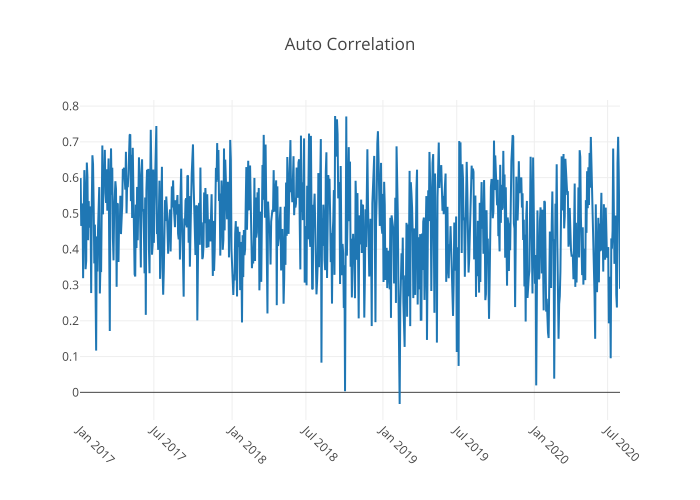

In [66]:
analysis_model.model_performance_graph(pred_label)